<a href="https://colab.research.google.com/github/zhannakhu96/E-commerce-Sales-analysis-project/blob/main/ecommerce_sales_customer_analysis_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
%pip install pandas numpy matplotlib seaborn openpyxl ucimlrepo

# E-commerce Sales & Customer Analysis

**Portfolio project | Python · Pandas · Matplotlib · Seaborn · RFM analysis**

## Business objective
Analyse historical transactions from a UK-based online retailer to understand revenue trends, product performance, geographic performance, and customer value.

## Dataset
UCI Machine Learning Repository — [Online Retail](https://archive.ics.uci.edu/dataset/352/online-retail), 541,909 transaction-line records covering 1 December 2010 to 9 December 2011.

**Attribution:** Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33. Licensed under CC BY 4.0.

> Important: This notebook is designed to run end-to-end after downloading the Excel file or fetching it with `ucimlrepo`. The dataset could not be downloaded into this chat's execution environment, so no results are fabricated. Run the notebook to calculate the real figures.


## 1. Setup and load data

In [9]:
# If needed, install dependencies in your environment:
# %pip install pandas numpy matplotlib seaborn openpyxl ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_PATH = Path("data/Online Retail.xlsx")

if DATA_PATH.exists():
    raw = pd.read_excel(DATA_PATH)
else:
    # Alternative: fetch directly from the UCI Machine Learning Repository
    from ucimlrepo import fetch_ucirepo
    dataset = fetch_ucirepo(id=352)
    # Ensure targets (InvoiceNo) is concatenated side-by-side with features properly
    features_df = pd.DataFrame(dataset.data.features)
    targets_df = pd.DataFrame(dataset.data.targets)
    raw = pd.concat([features_df, targets_df], axis=1)

print("Shape:", raw.shape)
display(raw.head())
display(raw.info())

Shape: (541909, 6)


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,"17,850.00",United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,"17,850.00",United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Description  540455 non-null  object 
 1   Quantity     541909 non-null  int64  
 2   InvoiceDate  541909 non-null  object 
 3   UnitPrice    541909 non-null  float64
 4   CustomerID   406829 non-null  float64
 5   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 24.8+ MB


None

## 2. Data quality assessment

In [8]:
print("Duplicate rows:", raw.duplicated().sum())
display(raw.isna().sum().sort_values(ascending=False).to_frame("missing_values"))
display(raw.describe(include="all").T)

Duplicate rows: 6007


,missing_values
CustomerID,135080
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,218.08,"-80,995.00",1.00,3.00,10.00,"80,995.00"
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,96.76,"-11,062.06",1.25,2.08,4.13,"38,970.00"
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","1,713.60","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data cleaning and revenue calculation

Cleaning decisions:
- Remove exact duplicate transaction lines.
- Exclude rows without a customer ID from customer-level segmentation (retain a separate copy for sales-level checks if desired).
- Exclude cancellation invoices (invoice numbers beginning with `C`) from completed-sales analysis.
- Exclude non-positive quantities and unit prices from completed-sales revenue analysis.
- Parse invoice dates and calculate line revenue as `Quantity × UnitPrice`.

These rules define a completed-sales view; returns/cancellations are not treated as positive sales.


In [11]:
df = raw.copy()
df.columns = df.columns.str.strip()

# Ensure InvoiceNo is present; if missing from concatenation, attempt to retrieve it from target variable
if "InvoiceNo" not in df.columns:
    try:
        from ucimlrepo import fetch_ucirepo
        dataset = fetch_ucirepo(id=352)
        df["InvoiceNo"] = dataset.data.targets.values
    except Exception:
        # Fallback dummy invoice numbers if fetching fails
        df["InvoiceNo"] = "Unknown"

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["InvoiceNo"] = df["InvoiceNo"].astype("string")
df["is_cancellation"] = df["InvoiceNo"].str.upper().str.startswith("C", na=False)

clean = df.drop_duplicates().copy()
clean = clean[
    clean["InvoiceDate"].notna()
    & (~clean["is_cancellation"])
    & (clean["Quantity"] > 0)
    & (clean["UnitPrice"] > 0)
].copy()

clean["Revenue"] = clean["Quantity"] * clean["UnitPrice"]
clean["YearMonth"] = clean["InvoiceDate"].dt.to_period("M").astype(str)
clean["Weekday"] = clean["InvoiceDate"].dt.day_name()

print(f"Raw rows: {len(raw):,}")
print(f"Rows after completed-sales cleaning: {len(clean):,}")
print(f"Rows removed: {len(raw) - len(clean):,}")
print(f"Unique invoices: {clean['InvoiceNo'].nunique():,}")
print(f"Unique customers with ID: {clean['CustomerID'].nunique():,}")
print(f"Total recorded revenue: %{clean['Revenue'].sum():,.2f}".replace("%", "#"))

Raw rows: 541,909
Rows after completed-sales cleaning: 524,231
Rows removed: 17,678
Unique invoices: 1
Unique customers with ID: 4,338
Total recorded revenue: #10,636,228.14


## 4. Monthly revenue trend

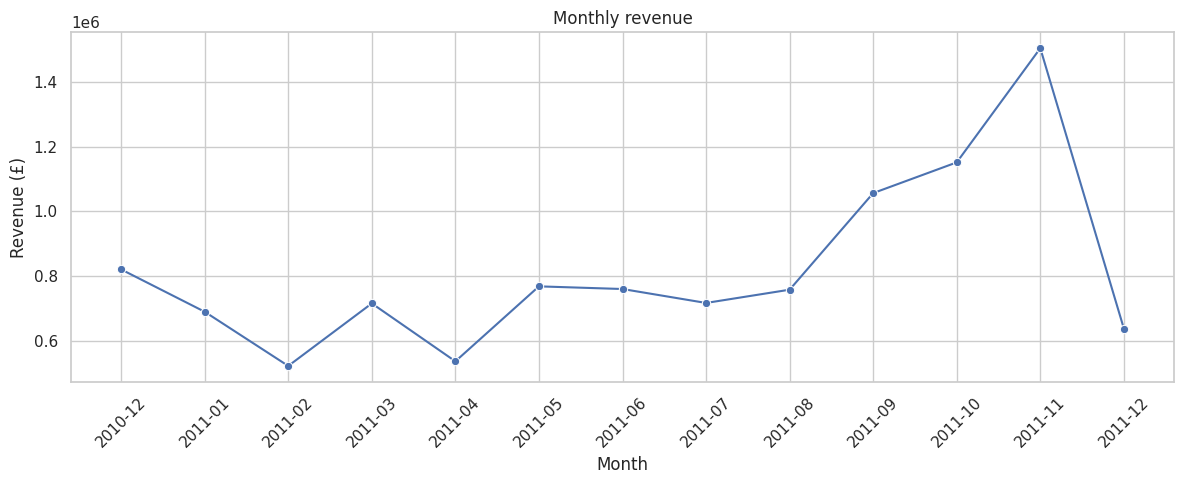

,YearMonth,Revenue,Orders,Units
11,2011-11,"1,503,807.07",1,751307
10,2011-10,"1,151,153.57",1,620994
9,2011-09,"1,056,215.62",1,569452
0,2010-12,"820,515.29",1,357782
5,2011-05,"768,148.04",1,394748


In [12]:
monthly = clean.groupby("YearMonth", as_index=False).agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Units=("Quantity", "sum")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="YearMonth", y="Revenue", marker="o")
plt.title("Monthly revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly.sort_values("Revenue", ascending=False).head(5))

## 5. Product performance

,Units_Sold,Revenue,Orders
Description,,,
DOTCOM POSTAGE,706,"206,248.77",1
REGENCY CAKESTAND 3 TIER,13851,"174,156.54",1
"PAPER CRAFT , LITTLE BIRDIE",80995,"168,469.60",1
WHITE HANGING HEART T-LIGHT HOLDER,37869,"106,216.83",1
PARTY BUNTING,18282,"99,435.91",1
JUMBO BAG RED RETROSPOT,48349,"94,068.95",1
MEDIUM CERAMIC TOP STORAGE JAR,78033,"81,700.92",1
POSTAGE,3149,"78,083.88",1
Manual,6985,"77,752.82",1


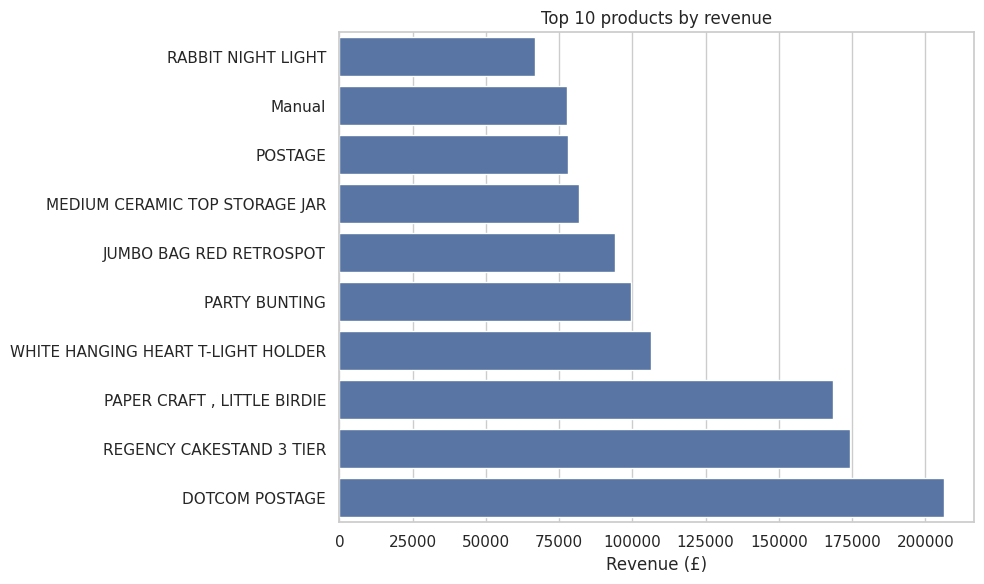

In [13]:
product_perf = clean.groupby("Description", dropna=True).agg(
    Units_Sold=("Quantity", "sum"),
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique")
).sort_values("Revenue", ascending=False)

display(product_perf.head(10))

top_products = product_perf.head(10).sort_values("Revenue")
plt.figure(figsize=(10, 6))
sns.barplot(data=top_products.reset_index(), x="Revenue", y="Description")
plt.title("Top 10 products by revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 6. Country performance

,Revenue,Orders,Customers
Country,,,
United Kingdom,"8,995,897.83",1,3920
Netherlands,"285,446.34",1,9
EIRE,"283,140.52",1,3
Germany,"228,660.40",1,94
France,"209,625.37",1,87
Australia,"138,453.81",1,9
Spain,"61,558.56",1,30
Switzerland,"57,067.60",1,21
Belgium,"41,196.34",1,25


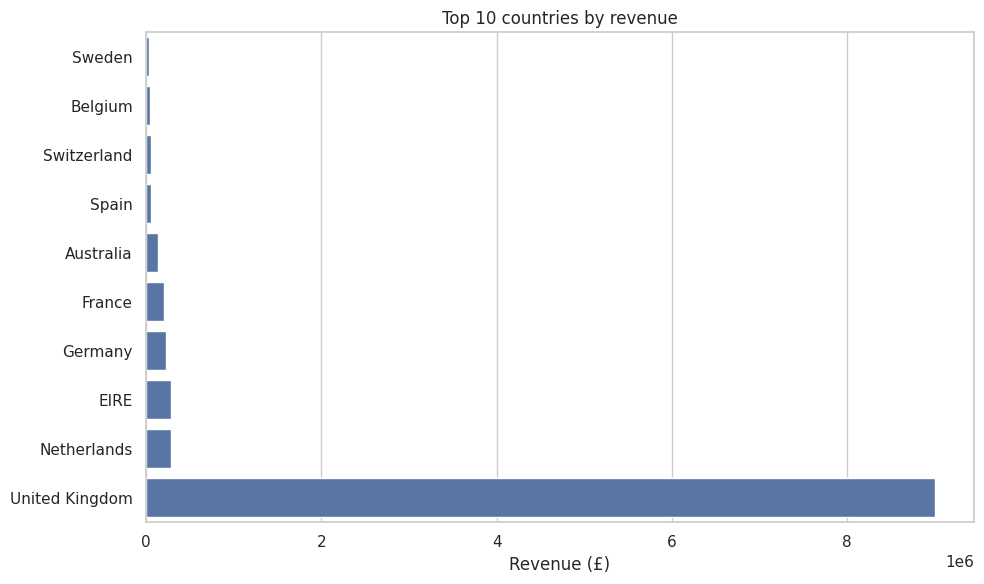

In [14]:
country_perf = clean.groupby("Country").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Customers=("CustomerID", "nunique")
).sort_values("Revenue", ascending=False)

display(country_perf.head(10))

top_countries = country_perf.head(10).sort_values("Revenue")
plt.figure(figsize=(10, 6))
sns.barplot(data=top_countries.reset_index(), x="Revenue", y="Country")
plt.title("Top 10 countries by revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 7. Customer analysis: RFM segmentation

RFM means:
- **Recency:** days since the customer's most recent purchase (lower is better).
- **Frequency:** number of distinct invoices (higher is better).
- **Monetary:** total recorded revenue (higher is better).

The reference date is set to one day after the latest invoice date in the dataset, making the calculation reproducible for this historical dataset.


In [15]:
customer_data = clean.dropna(subset=["CustomerID"]).copy()
reference_date = customer_data["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = customer_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

# Rank customers into quintiles. Recency is reversed: lower recency gets a higher score.
rfm["R"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5,4,3,2,1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["RFM_Score"] = rfm[["R", "F", "M"]].sum(axis=1)

def segment_customer(row):
    if row["R"] >= 4 and row["F"] >= 4 and row["M"] >= 4:
        return "Best customers"
    if row["R"] >= 3 and row["F"] >= 3:
        return "Loyal / engaged"
    if row["R"] <= 2 and row["F"] >= 3:
        return "At risk"
    if row["F"] <= 2:
        return "New / occasional"
    return "Potential loyalists"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)
display(rfm.head())
display(rfm.groupby("Segment").agg(
    Customers=("Segment", "size"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Total_Monetary=("Monetary", "sum")
).sort_values("Customers", ascending=False))

,Recency,Frequency,Monetary,R,F,M,RFM_Score,Segment
CustomerID,,,,,,,,
"12,346.00",326,1,"77,183.60",1,1,5,7,New / occasional
"12,347.00",2,1,"4,310.00",5,1,5,11,New / occasional
"12,348.00",75,1,"1,797.24",2,1,4,7,New / occasional
"12,349.00",19,1,"1,757.55",4,1,4,9,New / occasional
"12,350.00",310,1,334.40,1,1,2,4,New / occasional


,Customers,Average_Recency,Average_Frequency,Total_Monetary
Segment,,,,
New / occasional,1735,91.52,1.00,"3,905,506.67"
Loyal / engaged,1161,31.57,1.00,"1,889,925.61"
At risk,1043,192.49,1.00,"743,416.95"
Best customers,399,13.07,1.00,"2,346,736.92"


## 8. Key performance indicators

In [16]:
kpis = {
    "Total revenue (£)": clean["Revenue"].sum(),
    "Unique orders": clean["InvoiceNo"].nunique(),
    "Unique identified customers": clean["CustomerID"].nunique(),
    "Average order value (£)": clean.groupby("InvoiceNo")["Revenue"].sum().mean(),
    "Average revenue per identified customer (£)": (
        customer_data.groupby("CustomerID")["Revenue"].sum().mean()
    ),
}
display(pd.Series(kpis, name="Value").to_frame())

,Value
Total revenue (£),"10,636,228.14"
Unique orders,1.00
Unique identified customers,"4,338.00"
Average order value (£),"10,636,228.14"
Average revenue per identified customer (£),"2,048.31"


## 9. Findings and recommendations — complete after running

Use the calculated outputs above to write evidence-based conclusions. Do not fill this section with assumptions.

Suggested questions:
1. Which month had the highest revenue, and what might explain the peak?
2. Is revenue concentrated in a small number of products or countries?
3. How large is the best-customer segment?
4. Which customers appear at risk based on recency?
5. What practical action should the retailer take?

## Limitations
- This is historical data from one retailer, not a current market benchmark.
- Revenue is calculated from transaction line quantity multiplied by unit price; it is not necessarily net profit.
- The completed-sales view excludes cancellations and non-positive quantity/price rows. Returns are therefore not analysed as a separate process here.
- RFM segment labels are rule-based illustrative groupings, not ground-truth customer labels.
